<a href="https://colab.research.google.com/github/Slamm-alt/2318076_Islam_DataVisualization/blob/main/DataVisualization2318076.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Import Library dan Membaca Dataset

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Path dataset yang sudah dibersihkan
file_path = '/content/drive/MyDrive/Colab Notebooks/DatasetVisualization/cleaned_cafe_sales.csv'

# Membaca dataset
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv(file_path)

# Menampilkan 5 data pertama
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,Transaction ID Bersih,Transaction Date Standar
0,TXN_1000555,Tea,1,1.5,1.5,Credit Card,In-store,2023-10-19,TXN_1000555,19-10-2023
1,TXN_1001832,Salad,2,5.0,10.0,Cash,Takeaway,UNKNOWN,TXN_1001832,NaN
2,TXN_1002457,Cookie,5,1.0,5.0,Digital Wallet,Takeaway,2023-09-29,TXN_1002457,29-09-2023
3,TXN_1003246,Juice,2,3.0,6.0,NaN,NaN,2023-02-15,TXN_1003246,15-02-2023
4,TXN_1004184,Smoothie,1,4.0,4.0,Credit Card,In-store,2023-05-18,TXN_1004184,18-05-2023


#2. Pemeriksaan Dataset

In [6]:
# Melihat ukuran dataset
print("Jumlah baris dan kolom:", df.shape)

# Melihat nama kolom dan tipe data
df.info()

# Memeriksa nilai kosong
print("\nJumlah missing values:")
print(df.isnull().sum())

# Melihat statistik deskriptif
df.describe(include='all')

Jumlah baris dan kolom: (9859, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9859 entries, 0 to 9858
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Transaction ID            9859 non-null   object
 1   Item                      9526 non-null   object
 2   Quantity                  9721 non-null   object
 3   Price Per Unit            9680 non-null   object
 4   Total Spent               9686 non-null   object
 5   Payment Method            7317 non-null   object
 6   Location                  6644 non-null   object
 7   Transaction Date          9712 non-null   object
 8   Transaction ID Bersih     9859 non-null   object
 9   Transaction Date Standar  9428 non-null   object
dtypes: object(10)
memory usage: 770.4+ KB

Jumlah missing values:
Transaction ID                 0
Item                         333
Quantity                     138
Price Per Unit               179
Total Spent

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,Transaction ID Bersih,Transaction Date Standar
count,9859,9526,9721,9680,9686,7317,6644,9712,9859,9428
unique,9859,10,7,8,19,5,4,367,9859,365
top,TXN_9999124,Coffee,5,3.0,6.0,Digital Wallet,Takeaway,UNKNOWN,TXN_9999124,16-06-2023
freq,1,1151,1972,2384,965,2254,2978,146,1,40


#3. Pengolahan Tanggal dan Pembuatan Kolom Bulan

In [7]:
# Mengubah kolom tanggal menjadi format datetime
df['Transaction Date'] = pd.to_datetime(
    df['Transaction Date'],
    errors='coerce',
    dayfirst=True
)

# Mengubah Quantity dan Price Per Unit menjadi numerik
df['Quantity'] = pd.to_numeric(
    df['Quantity'], errors='coerce'
)

df['Price Per Unit'] = pd.to_numeric(
    df['Price Per Unit'], errors='coerce'
)

df['Total Spent'] = pd.to_numeric(
    df['Total Spent'], errors='coerce'
)

# Membuat kolom bulan
df['Transaction Month'] = (
    df['Transaction Date'].dt.to_period('M')
)

# Menampilkan hasil
df[['Transaction Date', 'Transaction Month']].head()

/tmp/ipykernel_601/2333032934.py:2: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df['Transaction Date'] = pd.to_datetime(


,Transaction Date,Transaction Month
0,2023-10-19,2023-10
1,NaT,NaT
2,2023-09-29,2023-09
3,2023-02-15,2023-02
4,2023-05-18,2023-05


#4. Menghitung GMV

In [8]:
# Menghitung GMV setiap transaksi
df['GMV'] = df['Quantity'] * df['Price Per Unit']

# Menampilkan hasil perhitungan
df[['Item', 'Quantity', 'Price Per Unit',
    'Total Spent', 'GMV']].head()

,Item,Quantity,Price Per Unit,Total Spent,GMV
0,Tea,1.0,1.5,1.5,1.5
1,Salad,2.0,5.0,10.0,10.0
2,Cookie,5.0,1.0,5.0,5.0
3,Juice,2.0,3.0,6.0,6.0
4,Smoothie,1.0,4.0,4.0,4.0


#5. Mengelompokkan GMV per Bulan

In [9]:
# Menghitung total GMV setiap bulan
monthly_sales = (
    df.dropna(subset=['Transaction Month', 'GMV'])
      .groupby('Transaction Month')['GMV']
      .sum()
      .sort_index()
)

# Menampilkan hasil agregasi
print("Total GMV per Bulan:")
print(monthly_sales)

Total GMV per Bulan:
Transaction Month
2023-01    6338.5
2023-02    5980.5
2023-03    6384.0
2023-04    6416.0
2023-05    6142.0
2023-06    6632.0
2023-07    6323.0
2023-08    6328.0
2023-09    6042.0
2023-10    6399.0
2023-11    6372.5
2023-12    6300.0
Freq: M, Name: GMV, dtype: float64


#6. Membuat Grafik Garis

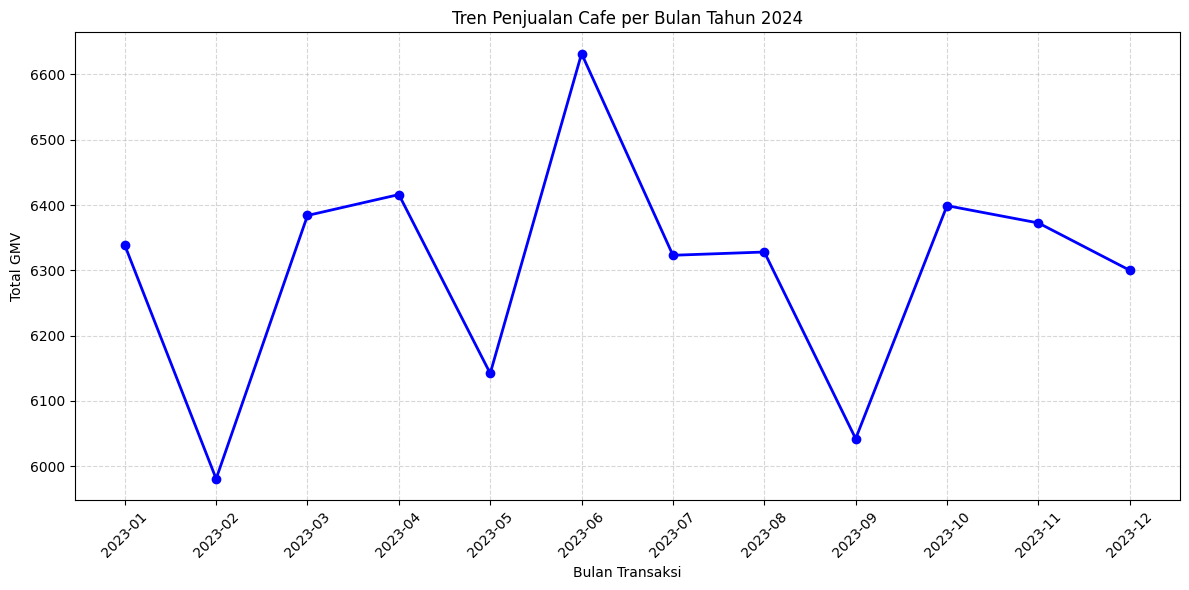

In [11]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    color='blue',
    linewidth=2,
    marker='o',
    linestyle='-'
)

plt.title('Tren Penjualan Cafe per Bulan Tahun 2024')
plt.xlabel('Bulan Transaksi')
plt.ylabel('Total GMV')
plt.xticks(rotation=45)

plt.grid(
    True,
    linestyle='--',
    alpha=0.5
)

plt.tight_layout()
plt.show()

* plt.figure(figsize=(12, 6)): Berfungsi untuk
mengatur ukuran kanvas atau area gambar grafik menjadi lebar 12 inci dan tinggi 6 inci agar data terlihat luas dan proporsional.

* plt.plot(...): Inti dari kode ini untuk menggambar grafik garis (linestyle='-') berwarna biru (color='blue') dengan ketebalan garis 2 (linewidth=2) dan menambahkan titik-titik lingkaran (marker='o') pada setiap nilai data bulanan.

* plt.title, plt.xlabel, plt.ylabel: Digunakan untuk memberikan judul utama grafik ("Tren Penjualan Cafe per Bulan Tahun 2024") serta label pada sumbu X (Bulan Transaksi) dan sumbu Y (Total GMV).

* plt.xticks(rotation=45): Memutar teks label nama-nama bulan pada sumbu X sebesar 45 derajat agar tidak saling bertumpuk dan lebih mudah dibaca.

* plt.grid(...): Menambahkan garis-garis latar belakang putus-putus (linestyle='--') dengan tingkat transparansi 50% (alpha=0.5) untuk memudahkan pembaca melihat nilai pada grafik secara sejajar.

* plt.tight_layout() dan plt.show(): tight_layout() merapikan tata letak elemen agar tidak ada teks yang terpotong, sedangkan plt.show() berfungsi untuk merender dan menampilkan hasil akhir visualisasinya di layar.

#7. Kustomisasi Grafik

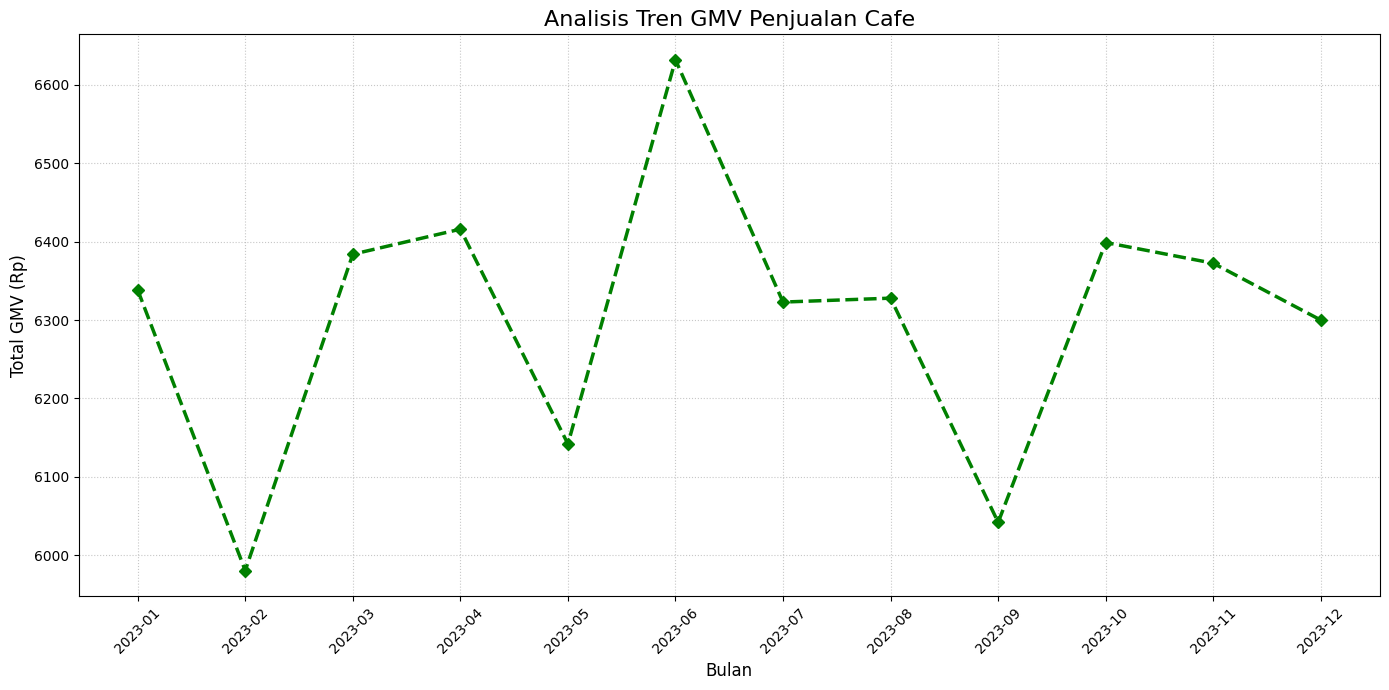

In [12]:
plt.figure(figsize=(14, 7))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    color='green',
    linewidth=2.5,
    marker='D',
    markersize=6,
    linestyle='--'
)

plt.title(
    'Analisis Tren GMV Penjualan Cafe',
    fontsize=16
)

plt.xlabel('Bulan', fontsize=12)
plt.ylabel('Total GMV (Rp)', fontsize=12)

plt.xticks(rotation=45)
plt.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

* Titik Puncak Penjualan (Peak Season): Penjualan tertinggi terjadi pada bulan Juni 2023 (2023-06) dengan Total GMV mencapai angka tertingginya di sekitar 6.630.

* Titik Terendah Penjualan (Low Season): Penjualan paling sepi atau terendah terjadi pada bulan Februari 2023 (2023-02) yang merosot tajam hingga mendekati angka 5.980.

* Fluktuasi yang Signifikan: Grafik menunjukkan pergerakan naik-turun yang cukup tajam, seperti penurunan drastis dari April ke Mei, lalu lonjakan ekstrem ke bulan Juni, serta penurunan dalam ke bulan September (sekitar 6.040).

* Pola Pemulihan dan Stabilitas: Setelah mengalami penurunan di bulan September, penjualan sempat bangkit kembali dan stabil di angka yang cukup tinggi pada bulan Oktober hingga November (berkisar di angka 6.370–6.400) sebelum akhirnya melandai ke angka 6.300 pada Desember.

#8. Menambahkan Anotasi

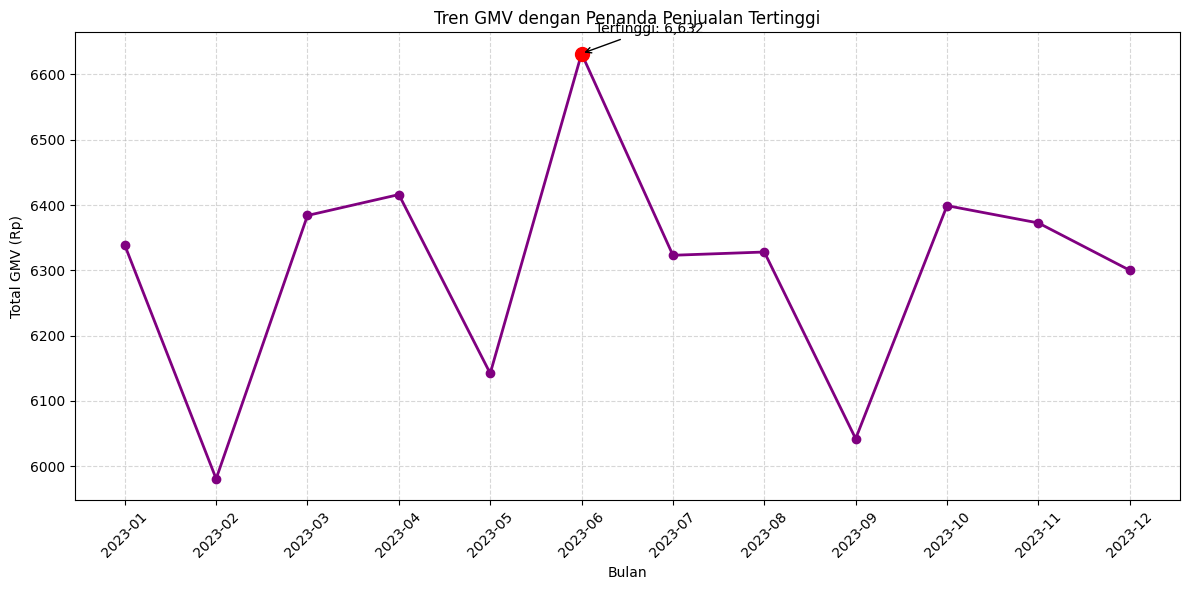

In [13]:
if not monthly_sales.empty:
    plt.figure(figsize=(12, 6))

    plt.plot(
        monthly_sales.index.astype(str),
        monthly_sales.values,
        color='purple',
        linewidth=2,
        marker='o'
    )

    # Menandai bulan dengan GMV tertinggi
    max_month = monthly_sales.idxmax()
    max_value = monthly_sales.max()
    max_position = monthly_sales.index.get_loc(max_month)

    plt.scatter(
        max_position,
        max_value,
        color='red',
        s=100,
        zorder=3
    )

    plt.annotate(
        f'Tertinggi: {max_value:,.0f}',
        xy=(max_position, max_value),
        xytext=(10, 15),
        textcoords='offset points',
        arrowprops=dict(arrowstyle='->')
    )

    plt.title('Tren GMV dengan Penanda Penjualan Tertinggi')
    plt.xlabel('Bulan')
    plt.ylabel('Total GMV (Rp)')
    plt.xticks(
        range(len(monthly_sales)),
        monthly_sales.index.astype(str),
        rotation=45
    )
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada data GMV bulanan yang bisa divisualisasikan.")

* Puncak Penjualan Tertinggi (Peak Season): Penjualan tertinggi secara signifikan dicapai pada bulan Juni 2023 (2023-06) dengan Total GMV menyentuh angka 6.632, yang ditandai secara khusus dengan titik merah dan anotasi pada grafik.   

* Titik Terendah Penjualan (Low Season): Penjualan paling sepi terjadi pada bulan Februari 2023 (2023-02) yang merosot tajam ke titik terendahnya di angka sekitar 5.980.   

* Fluktuasi yang Volatil: Pergerakan grafik menunjukkan ketidakstabilan bulanan yang cukup drastis, seperti penurunan tajam dari bulan April ke Mei, lonjakan ekstrem ke bulan Juni, serta penurunan dalam kembali pada bulan September ke angka sekitar 6.040.  

* Pola Pemulihan Kuartal Akhir: Setelah sempat anjlok di bulan September, performa penjualan kembali pulih dan bertahan stabil di angka yang cukup tinggi pada bulan Oktober (sekitar 6.400) dan November (sekitar 6.370) sebelum akhirnya ditutup melandai pada bulan Desember di angka 6.300.

#9. Visualisasi Produk Terlaris

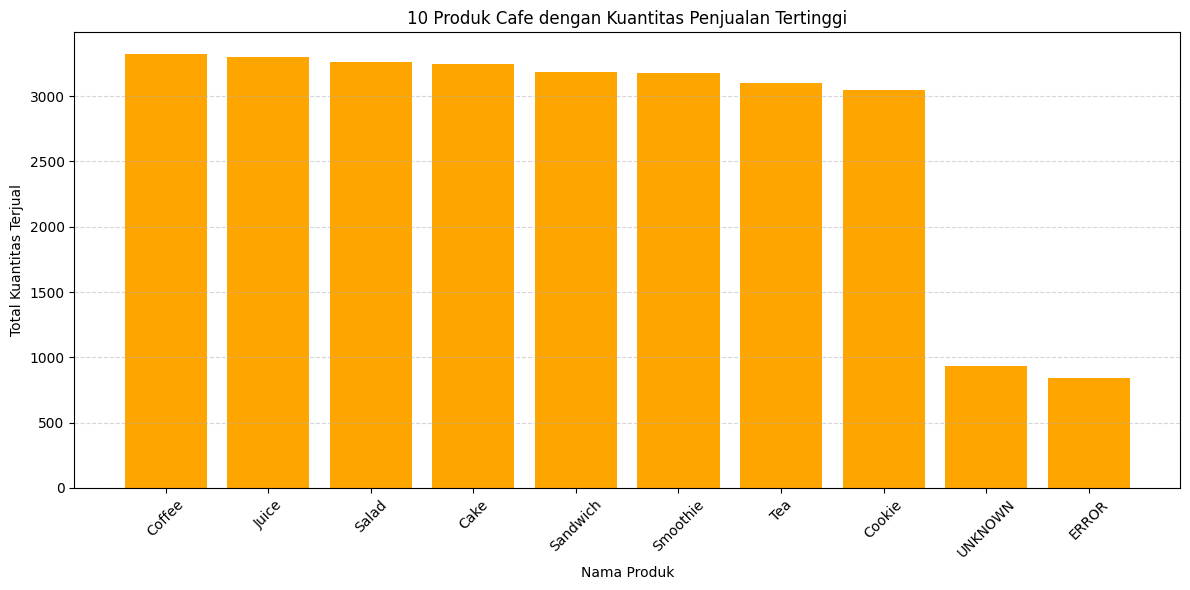

In [14]:
# Menghitung total kuantitas terjual per item
item_sales = (
    df.dropna(subset=['Item', 'Quantity'])
      .groupby('Item')['Quantity']
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(12, 6))

plt.bar(
    item_sales.index,
    item_sales.values,
    color='orange'
)

plt.title('10 Produk Cafe dengan Kuantitas Penjualan Tertinggi')
plt.xlabel('Nama Produk')
plt.ylabel('Total Kuantitas Terjual')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

* Produk Terlaris (Top Products): Produk Coffee memimpin sebagai barang dengan total kuantitas penjualan tertinggi, yang diikuti secara sangat ketat oleh Juice, Salad, dan Cake di posisi-posisi teratas dengan selisih angka penjualan yang tidak terlalu jauh.   

* Kategori Penjualan yang Stabil: Sebagian besar produk utama seperti Sandwich, Smoothie, Tea, dan Cookie memiliki tingkat penjualan yang tinggi dan konsisten, masing-masing berada di atas kisaran 3.000 kuantitas terjual.   

* Anomali Data (UNKNOWN & ERROR): Terdapat kategori data yang tidak valid atau bermasalah pada sistem pencatatan, yaitu UNKNOWN dan ERROR, yang masing-masing tercatat memiliki kuantitas di bawah 1.000.   

* Rekomendasi Tindak Lanjut: Tingginya penjualan pada kategori makanan dan minuman utama menunjukkan produk-produk tersebut sangat diminati, namun perlu dilakukan pembersihan data (data cleaning) untuk menyelidiki penyebab munculnya label UNKNOWN dan ERROR agar laporan inventaris kafe menjadi akurat.  

#10. Visualisasi Metode Pembayaran

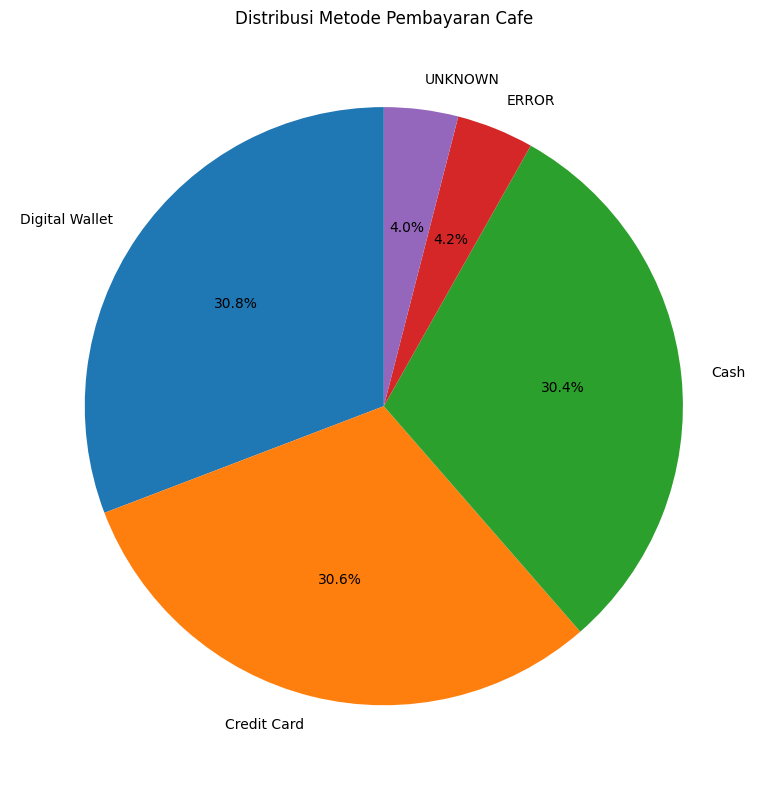

In [15]:
payment_counts = df['Payment Method'].dropna().value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribusi Metode Pembayaran Cafe')
plt.tight_layout()
plt.show()

* Metode Pembayaran Utama (Dominant Payment Methods): Tiga metode pembayaran teratas sangat mendominasi dengan porsi yang hampir seimbang, yaitu Digital Wallet sebesar 30.8%, Credit Card sebesar 30.6%, dan Cash sebesar 30.4%.   

* Keseimbangan Preferensi Pelanggan: Penggunaan dompet digital, kartu kredit, dan tunai menunjukkan bahwa pelanggan kafe memiliki preferensi yang sangat beragam namun terbagi secara merata dalam hal cara mereka melakukan pembayaran.   

* Adanya Masalah Data (ERROR & UNKNOWN): Terdapat persentase transaksi yang bermasalah pada sistem, di mana kategori ERROR tercatat sebesar 4.2% dan UNKNOWN sebesar 4.0%.   

* Rekomendasi Tindak Lanjut: Meskipun metode pembayaran utama berjalan dengan baik, pihak kafe perlu segera melakukan audit pada sistem pencatatan transaksi untuk mengatasi porsi ERROR dan UNKNOWN yang jika ditotal mencapai 8.2% agar laporan keuangan dan kas menjadi valid.

#11. Visualisasi Lokasi Transaksi

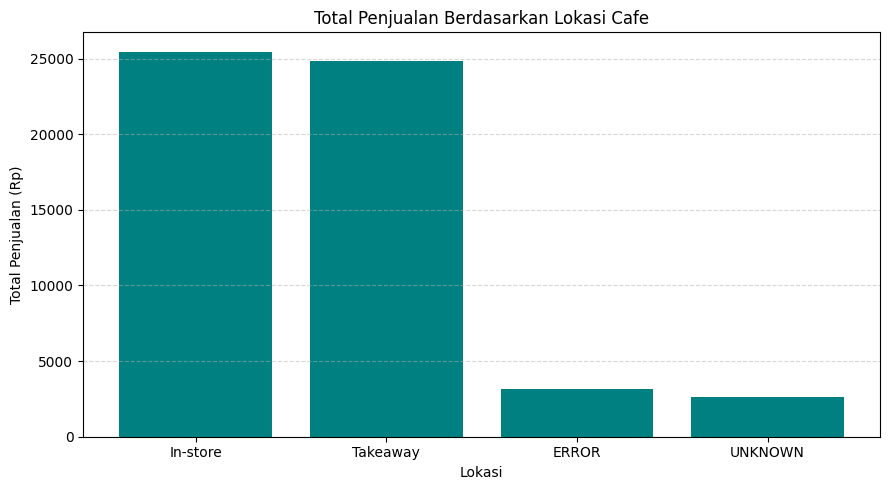

In [16]:
location_sales = (
    df.dropna(subset=['Location', 'Total Spent'])
      .groupby('Location')['Total Spent']
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

plt.bar(
    location_sales.index,
    location_sales.values,
    color='teal'
)

plt.title('Total Penjualan Berdasarkan Lokasi Cafe')
plt.xlabel('Lokasi')
plt.ylabel('Total Penjualan (Rp)')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

* Lokasi Penjualan Utama (Dominant Order Types): Penjualan tertinggi didominasi oleh kategori In-store (makan di tempat) yang berada sedikit di atas angka 25.000, diikuti secara sangat ketat oleh kategori Takeaway (bawa pulang) di kisaran angka 24.800–25.000.   

* Keseimbangan Model Layanan: Kontribusi antara pelanggan yang makan di tempat (In-store) dan yang membawa pulang (Takeaway) hampir seimbang, menunjukkan bahwa kedua tipe layanan ini sama-sama menjadi pilar utama pendapatan kafe.

* Anomali Pencatatan Data (ERROR & UNKNOWN): Terdapat data transaksi yang tidak teridentifikasi dengan benar pada sistem, di mana lokasi ERROR tercatat sedikit di atas 3.000 dan UNKNOWN tercatat mendekati angka 2.800–3.000.

* Rekomendasi Tindak Lanjut: Pihak operasional perlu mempertahankan kualitas ruang/fasilitas In-store sekaligus efisiensi pengemasan Takeaway, serta melakukan evaluasi pada sistem POS (Point of Sale) untuk memperbaiki masalah keterangan data ERROR dan UNKNOWN agar pencatatan tipe pemesanan menjadi lebih akurat.